# MSCS 634 – Lab 6: Association Rule Mining

**Name:** Urusha Budhathoki

**Course:** MSCS-634-M50 Advanced Bid Data and Data Mining

**Lab Assignment:** Association Rule Mining with Apriori and FP-Growth

## Introduction

This lab investigates association rule mining through the Apriori and FP-Growth methods. The UCI Online Retail database is used to identify frequent purchases and establish associations between items. Seaborn graphs are used to interpret results.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

# Set visualization style
sns.set_theme(style="whitegrid")

# Load the Online Retail dataset
df = pd.read_excel("Online Retail.xlsx")

# Display the first five rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Display column information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset shape: (541909, 8)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records: 5268


In [3]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove missing product descriptions
df_clean = df_clean.dropna(subset=["Description"])

# Remove cancelled transactions
df_clean = df_clean[~df_clean["InvoiceNo"].astype(str).str.startswith("C")]

# Remove records with invalid quantities and prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

# Remove extra spaces from product descriptions
df_clean["Description"] = df_clean["Description"].str.strip()

# Display cleaned dataset information
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Remaining missing values:")
print(df_clean.isnull().sum())

Original dataset shape: (541909, 8)
Cleaned dataset shape: (530104, 8)
Remaining missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132220
Country             0
dtype: int64


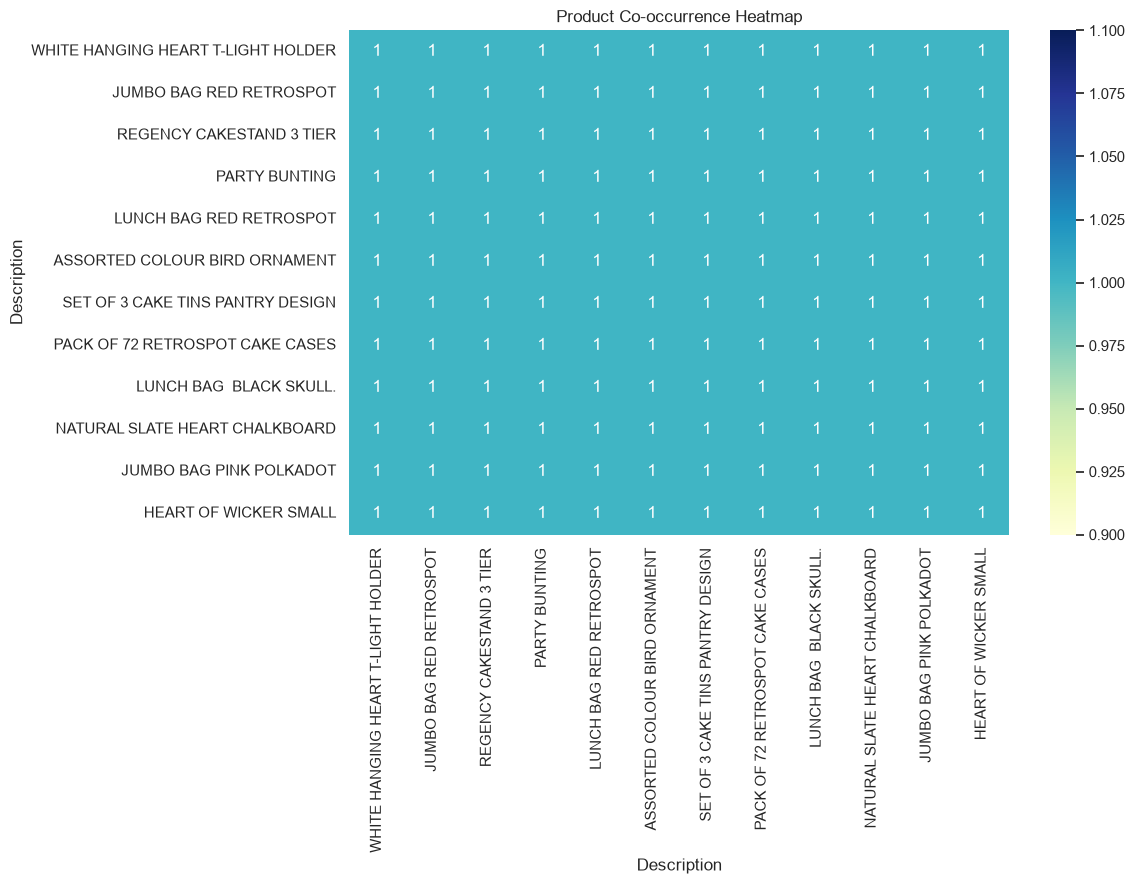

In [9]:
# Create transaction-level product data

basket_data = (
    df_clean.groupby(["InvoiceNo", "Description"])["Quantity"]
    .sum()
    .unstack(fill_value=0)
)

# Convert quantities into binary values
basket_data = (basket_data > 0).astype(bool)

# Select the 12 most frequently purchased products
top_items = basket_data.sum().sort_values(ascending=False).head(12).index

# Create co-occurrence matrix
co_occurrence = basket_data[top_items].T.dot(basket_data[top_items])

# Create heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    co_occurrence,
    annot=True,
    fmt="g",
    cmap="YlGnBu"
)

plt.title("Product Co-occurrence Heatmap")
plt.tight_layout()
plt.show()

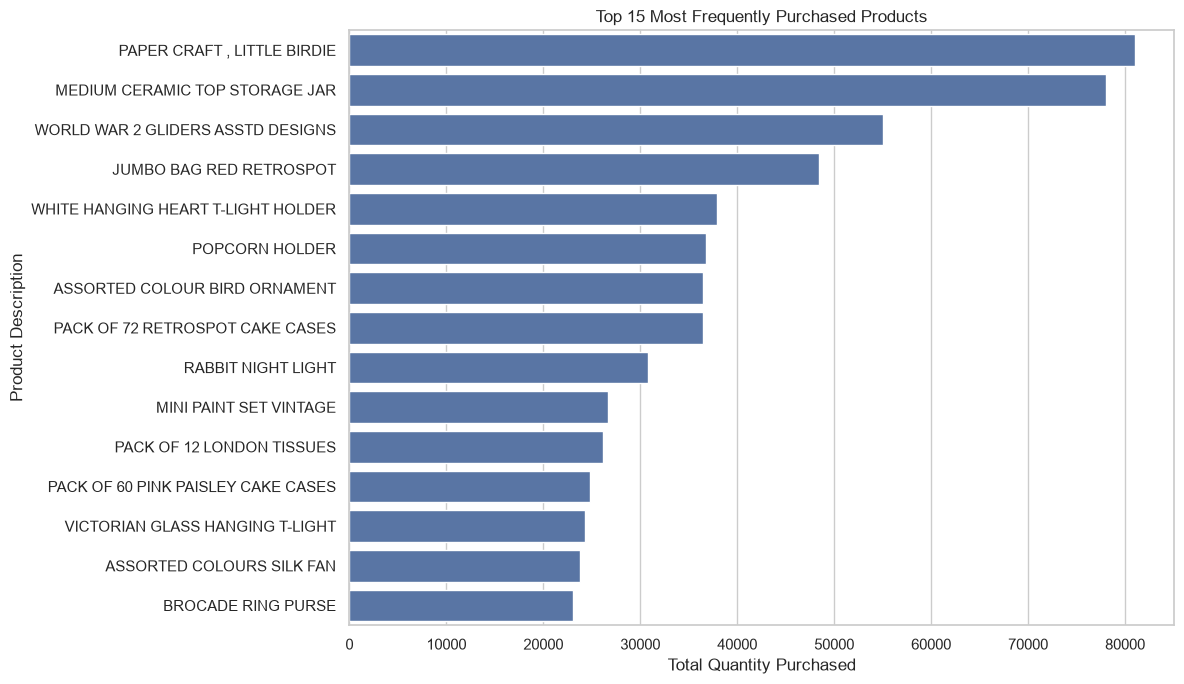

In [5]:
# Find the 15 most frequently purchased products

top_products = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

# Create barplot
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products,
    x="Quantity",
    y="Description"
)

plt.title("Top 15 Most Frequently Purchased Products")
plt.xlabel("Total Quantity Purchased")
plt.ylabel("Product Description")
plt.tight_layout()
plt.show()

In [6]:
# Prepare transaction basket for Apriori and FP-Growth

print("Transaction basket shape:", basket_data.shape)

print("\nNumber of transactions:", basket_data.shape[0])
print("Number of unique products:", basket_data.shape[1])

# Display first five transactions
display(basket_data.head())

Transaction basket shape: (19960, 4015)

Number of transactions: 19960
Number of unique products: 4015


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,...,ZINC STAR T-LIGHT HOLDER,ZINC SWEETHEART SOAP DISH,ZINC SWEETHEART WIRE LETTER RACK,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC TOP 2 DOOR WOODEN SHELF,ZINC WILLIE WINKIE CANDLE STICK,ZINC WIRE KITCHEN ORGANISER,ZINC WIRE SWEETHEART LETTER TRAY
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536366,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536367,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536368,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536369,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [10]:
# Apply Apriori algorithm

start_time = time.time()

frequent_itemsets_apriori = apriori(
    basket_data,
    min_support=0.02,
    use_colnames=True,
    max_len=3,
    low_memory=True
)

apriori_time = time.time() - start_time

# Display frequent itemsets
print("Apriori Execution Time:", round(apriori_time, 4), "seconds")
print("Number of frequent itemsets:", len(frequent_itemsets_apriori))

display(
    frequent_itemsets_apriori.sort_values(
        by="support",
        ascending=False
    ).head(20)
)

Apriori Execution Time: 1.5223 seconds
Number of frequent itemsets: 379


,support,itemsets
277,0.113026,frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
103,0.104659,frozenset({JUMBO BAG RED RETROSPOT})
199,0.099599,frozenset({REGENCY CAKESTAND 3 TIER})
158,0.084419,frozenset({PARTY BUNTING})
128,0.078357,frozenset({LUNCH BAG RED RETROSPOT})
15,0.072896,frozenset({ASSORTED COLOUR BIRD ORNAMENT})
221,0.069389,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN})
150,0.066132,frozenset({PACK OF 72 RETROSPOT CAKE CASES})
121,0.063778,frozenset({LUNCH BAG BLACK SKULL.})
140,0.062575,frozenset({NATURAL SLATE HEART CHALKBOARD})


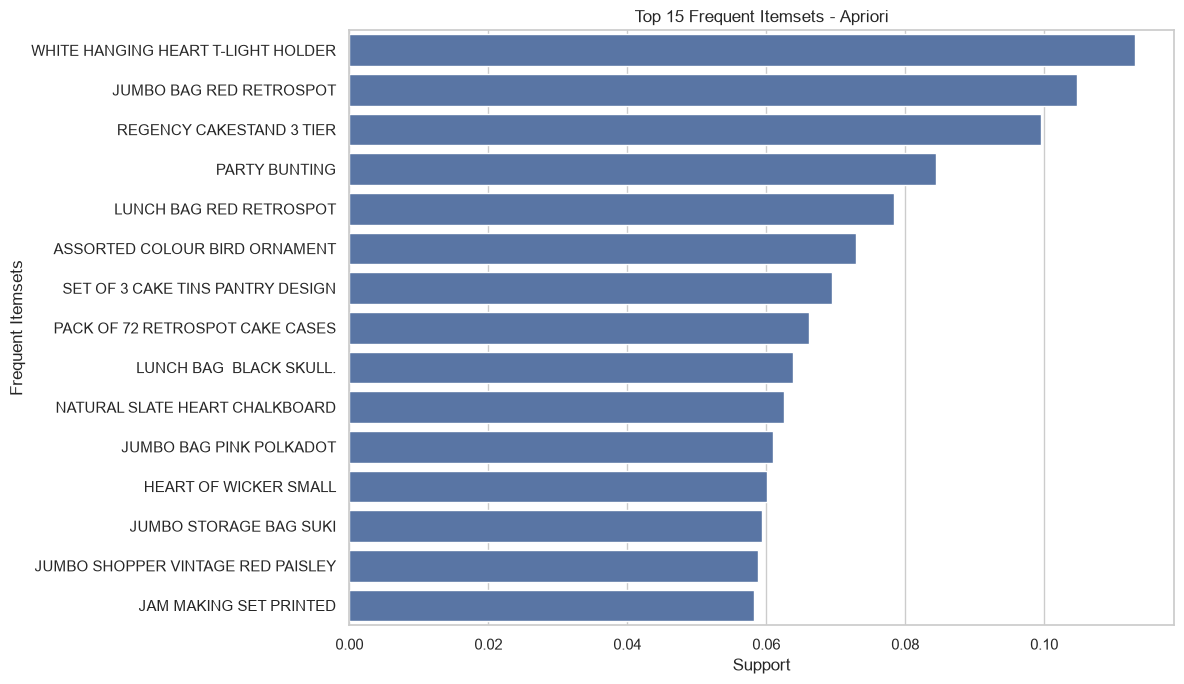

In [11]:
# Visualize top 15 frequent itemsets from Apriori

top_apriori = frequent_itemsets_apriori.sort_values(
    by="support",
    ascending=False
).head(15).copy()

top_apriori["itemsets"] = top_apriori["itemsets"].apply(
    lambda x: ", ".join(list(x))
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_apriori,
    x="support",
    y="itemsets"
)

plt.title("Top 15 Frequent Itemsets - Apriori")
plt.xlabel("Support")
plt.ylabel("Frequent Itemsets")
plt.tight_layout()
plt.show()

In [12]:
# Apply FP-Growth algorithm

start_time = time.time()

frequent_itemsets_fpgrowth = fpgrowth(
    basket_data,
    min_support=0.02,
    use_colnames=True,
    max_len=3
)

fpgrowth_time = time.time() - start_time

# Display FP-Growth results
print("FP-Growth Execution Time:", round(fpgrowth_time, 4), "seconds")

print("Number of frequent itemsets:", len(frequent_itemsets_fpgrowth))

display(
    frequent_itemsets_fpgrowth.sort_values(
        by="support",
        ascending=False
    ).head(20)
)

FP-Growth Execution Time: 4.3566 seconds
Number of frequent itemsets: 379


,support,itemsets
0,0.113026,frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
67,0.104659,frozenset({JUMBO BAG RED RETROSPOT})
164,0.099599,frozenset({REGENCY CAKESTAND 3 TIER})
235,0.084419,frozenset({PARTY BUNTING})
30,0.078357,frozenset({LUNCH BAG RED RETROSPOT})
4,0.072896,frozenset({ASSORTED COLOUR BIRD ORNAMENT})
246,0.069389,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN})
31,0.066132,frozenset({PACK OF 72 RETROSPOT CAKE CASES})
109,0.063778,frozenset({LUNCH BAG BLACK SKULL.})
57,0.062575,frozenset({NATURAL SLATE HEART CHALKBOARD})


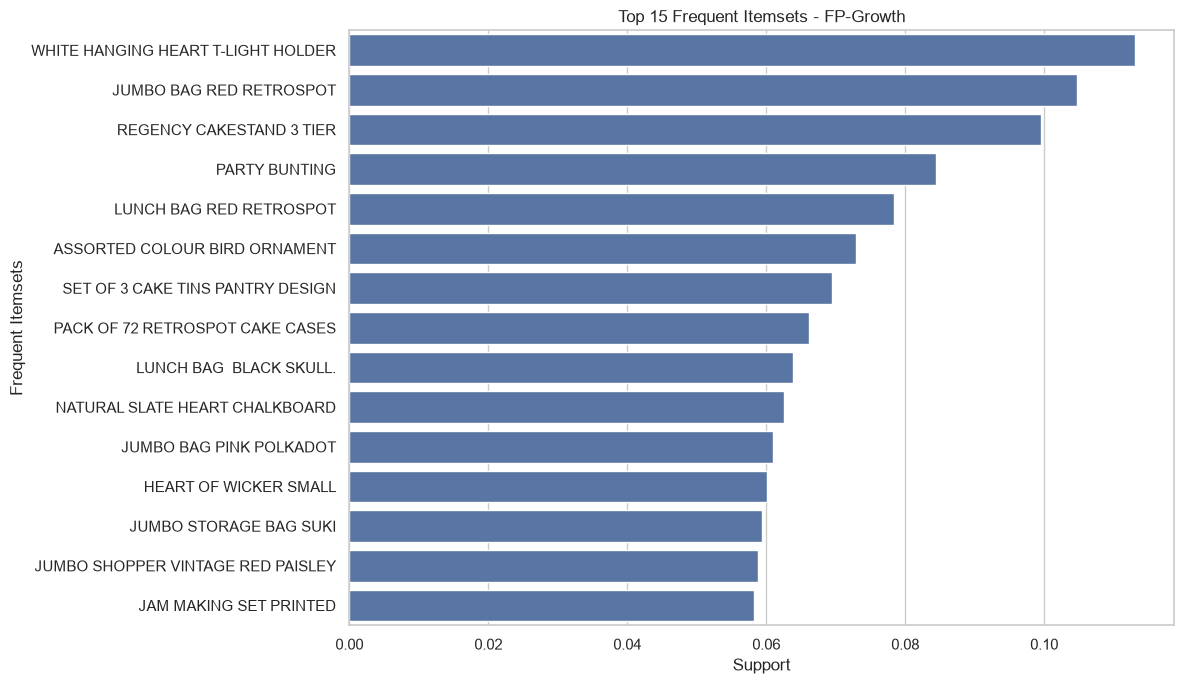

In [13]:
# Visualize top 15 frequent itemsets from FP-Growth

top_fpgrowth = frequent_itemsets_fpgrowth.sort_values(
    by="support",
    ascending=False
).head(15).copy()

top_fpgrowth["itemsets"] = top_fpgrowth["itemsets"].apply(
    lambda x: ", ".join(list(x))
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_fpgrowth,
    x="support",
    y="itemsets"
)

plt.title("Top 15 Frequent Itemsets - FP-Growth")
plt.xlabel("Support")
plt.ylabel("Frequent Itemsets")
plt.tight_layout()
plt.show()

,Algorithm,Execution Time (seconds),Frequent Itemsets
0,Apriori,1.522276,379
1,FP-Growth,4.356554,379


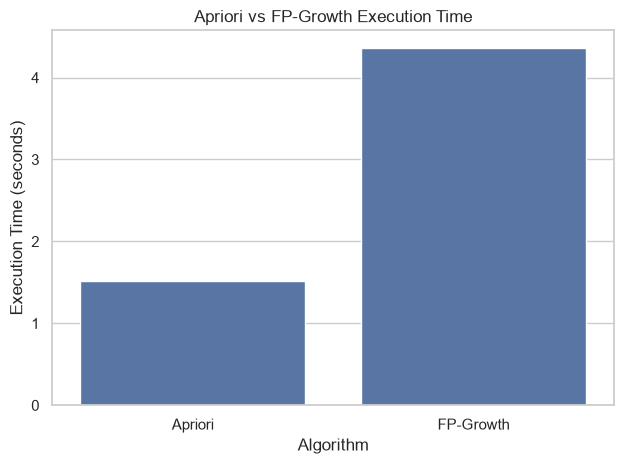

In [14]:
# Compare Apriori and FP-Growth performance

comparison = pd.DataFrame({
    "Algorithm": ["Apriori", "FP-Growth"],
    "Execution Time (seconds)": [apriori_time, fpgrowth_time],
    "Frequent Itemsets": [
        len(frequent_itemsets_apriori),
        len(frequent_itemsets_fpgrowth)
    ]
})

display(comparison)

sns.barplot(
    data=comparison,
    x="Algorithm",
    y="Execution Time (seconds)"
)

plt.title("Apriori vs FP-Growth Execution Time")
plt.tight_layout()
plt.show()

In [15]:
# Generate association rules using Apriori frequent itemsets

rules_apriori = association_rules(
    frequent_itemsets_apriori,
    metric="confidence",
    min_threshold=0.3
)

# Display important association metrics
print("Number of Apriori association rules:", len(rules_apriori))

display(
    rules_apriori[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].sort_values(
        by="lift",
        ascending=False
    ).head(20)
)

Number of Apriori association rules: 151


,antecedents,consequents,support,confidence,lift
137,"frozenset({ROSES REGENCY TEACUP AND SAUCER, GR...",frozenset({PINK REGENCY TEACUP AND SAUCER}),0.027104,0.705346,18.403524
138,frozenset({PINK REGENCY TEACUP AND SAUCER}),"frozenset({ROSES REGENCY TEACUP AND SAUCER, GR...",0.027104,0.707190,18.403524
140,frozenset({GREEN REGENCY TEACUP AND SAUCER}),"frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...",0.027104,0.534057,17.825724
135,"frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...",frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.027104,0.904682,17.825724
23,frozenset({PINK REGENCY TEACUP AND SAUCER}),frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.031663,0.826144,16.278213
24,frozenset({GREEN REGENCY TEACUP AND SAUCER}),frozenset({PINK REGENCY TEACUP AND SAUCER}),0.031663,0.623889,16.278213
139,frozenset({ROSES REGENCY TEACUP AND SAUCER}),"frozenset({PINK REGENCY TEACUP AND SAUCER, GRE...",0.027104,0.507981,16.043204
136,"frozenset({PINK REGENCY TEACUP AND SAUCER, GRE...",frozenset({ROSES REGENCY TEACUP AND SAUCER}),0.027104,0.856013,16.043204
22,frozenset({GARDENERS KNEELING PAD CUP OF TEA}),frozenset({GARDENERS KNEELING PAD KEEP CALM}),0.027355,0.720317,15.747557
21,frozenset({GARDENERS KNEELING PAD KEEP CALM}),frozenset({GARDENERS KNEELING PAD CUP OF TEA}),0.027355,0.598028,15.747557


In [16]:
# Generate association rules using FP-Growth frequent itemsets

rules_fpgrowth = association_rules(
    frequent_itemsets_fpgrowth,
    metric="confidence",
    min_threshold=0.3
)

print("Number of FP-Growth association rules:", len(rules_fpgrowth))

display(
    rules_fpgrowth[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].sort_values(
        by="lift",
        ascending=False
    ).head(20)
)

Number of FP-Growth association rules: 151


,antecedents,consequents,support,confidence,lift
122,frozenset({PINK REGENCY TEACUP AND SAUCER}),"frozenset({ROSES REGENCY TEACUP AND SAUCER, GR...",0.027104,0.707190,18.403524
121,"frozenset({ROSES REGENCY TEACUP AND SAUCER, GR...",frozenset({PINK REGENCY TEACUP AND SAUCER}),0.027104,0.705346,18.403524
119,"frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...",frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.027104,0.904682,17.825724
124,frozenset({GREEN REGENCY TEACUP AND SAUCER}),"frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...",0.027104,0.534057,17.825724
115,frozenset({PINK REGENCY TEACUP AND SAUCER}),frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.031663,0.826144,16.278213
116,frozenset({GREEN REGENCY TEACUP AND SAUCER}),frozenset({PINK REGENCY TEACUP AND SAUCER}),0.031663,0.623889,16.278213
120,"frozenset({PINK REGENCY TEACUP AND SAUCER, GRE...",frozenset({ROSES REGENCY TEACUP AND SAUCER}),0.027104,0.856013,16.043204
123,frozenset({ROSES REGENCY TEACUP AND SAUCER}),"frozenset({PINK REGENCY TEACUP AND SAUCER, GRE...",0.027104,0.507981,16.043204
149,frozenset({GARDENERS KNEELING PAD KEEP CALM}),frozenset({GARDENERS KNEELING PAD CUP OF TEA}),0.027355,0.598028,15.747557
150,frozenset({GARDENERS KNEELING PAD CUP OF TEA}),frozenset({GARDENERS KNEELING PAD KEEP CALM}),0.027355,0.720317,15.747557


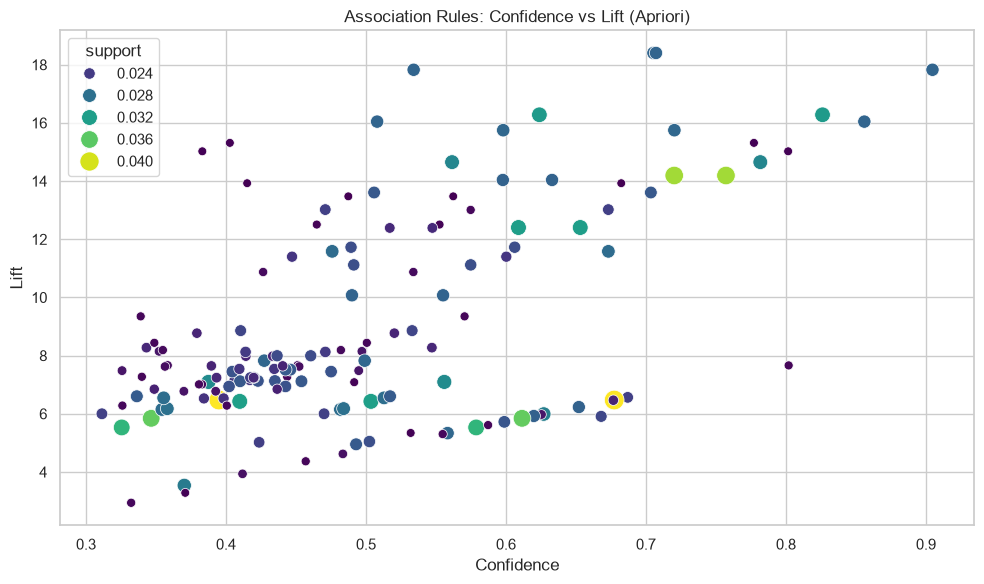

In [17]:
# Visualize confidence versus lift for Apriori rules

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rules_apriori,
    x="confidence",
    y="lift",
    size="support",
    hue="support",
    palette="viridis",
    sizes=(40, 200)
)

plt.title("Association Rules: Confidence vs Lift (Apriori)")
plt.xlabel("Confidence")
plt.ylabel("Lift")
plt.tight_layout()
plt.show()

In [18]:
# Compare the association rules from both algorithms

print("Apriori Rules:", len(rules_apriori))
print("FP-Growth Rules:", len(rules_fpgrowth))

print("\nTop 5 Apriori Rules:")

display(
    rules_apriori[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].sort_values(
        by="lift",
        ascending=False
    ).head(5)
)

Apriori Rules: 151
FP-Growth Rules: 151

Top 5 Apriori Rules:


,antecedents,consequents,support,confidence,lift
137,"frozenset({ROSES REGENCY TEACUP AND SAUCER, GR...",frozenset({PINK REGENCY TEACUP AND SAUCER}),0.027104,0.705346,18.403524
138,frozenset({PINK REGENCY TEACUP AND SAUCER}),"frozenset({ROSES REGENCY TEACUP AND SAUCER, GR...",0.027104,0.707190,18.403524
140,frozenset({GREEN REGENCY TEACUP AND SAUCER}),"frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...",0.027104,0.534057,17.825724
135,"frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...",frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.027104,0.904682,17.825724
23,frozenset({PINK REGENCY TEACUP AND SAUCER}),frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.031663,0.826144,16.278213


In [19]:
# Compare Apriori and FP-Growth results

print("========== ALGORITHM COMPARISON ==========")

print("\nApriori:")
print("Execution time:", round(apriori_time, 4), "seconds")
print("Frequent itemsets:", len(frequent_itemsets_apriori))
print("Association rules:", len(rules_apriori))

print("\nFP-Growth:")
print("Execution time:", round(fpgrowth_time, 4), "seconds")
print("Frequent itemsets:", len(frequent_itemsets_fpgrowth))
print("Association rules:", len(rules_fpgrowth))

# Identify the faster algorithm
if apriori_time < fpgrowth_time:
    print("\nApriori was faster.")
else:
    print("\nFP-Growth was faster.")

# Verify whether both algorithms found matching itemsets
apriori_supports = {
    frozenset(items): support
    for items, support in zip(
        frequent_itemsets_apriori["itemsets"],
        frequent_itemsets_apriori["support"]
    )
}

fpgrowth_supports = {
    frozenset(items): support
    for items, support in zip(
        frequent_itemsets_fpgrowth["itemsets"],
        frequent_itemsets_fpgrowth["support"]
    )
}

print(
    "\nDo both algorithms produce matching itemsets?",
    apriori_supports.keys() == fpgrowth_supports.keys()
)

========== ALGORITHM COMPARISON ==========

Apriori:
Execution time: 1.5223 seconds
Frequent itemsets: 379
Association rules: 151

FP-Growth:
Execution time: 4.3566 seconds
Frequent itemsets: 379
Association rules: 151

Apriori was faster.

Do both algorithms produce matching itemsets? True


## Comparative Analysis

Apriori and FP-Growth techniques were applied to perform mining on the Online Retail dataset, using a support threshold of 0.02 and an itemset length of 3.

The time taken by both techniques was analyzed to assess their performance. For the Apriori technique, the time taken was 1.5223 seconds, and for FP-Growth, it was 4.3566 seconds. Both techniques generated 379 frequent itemsets and 151 association rules. It was found that both techniques had the same frequent itemsets.

In this case, Apriori technique was better than FP-Growth in terms of speed.


## Challenges Faced

One of the challenges was cleaning the transaction dataset. This required looking at missing product descriptions, canceled invoices, duplicate transactions, and incorrect quantities.

The other challenge was transforming the transaction data into a basket data format, which was necessary to perform frequent itemset mining.

These challenges were addressed using Pandas data-cleaning operations and transaction-level grouping.

## Conclusion

Association rule mining has been performed on the data in this lab using two approaches: Apriori and FP-Growth. This analysis showed that transaction data can be used to find associations between different products.

Support, confidence, and lift were used to find out the significance and value of association rules. Seaborn plots were used to better explain the findings.